# 02 · Dados, splits e compressão latente

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


6000 imagens de treino, 1000 de validação e 1000 de teste. Treino/validação vêm do train oficial, teste do t10k. Imagens 28×28 são reduzidas por média de área a 14×14. PCA e whitening são ajustados somente no treino. A condição é a classe.

In [2]:
data = exp.prepare_data()
for split in ['train', 'val', 'test']:
    print(split, data[f'{split}_images'].shape, np.bincount(data[f'{split}_labels']).tolist())
assert not np.intersect1d(data['train_source_indices'], data['val_source_indices']).size
print(json.dumps(json.loads((ROOT / 'data/provenance.json').read_text()), indent=2, ensure_ascii=False))

train (6000, 196) [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
val (1000, 196) [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
test (1000, 196) [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
{
  "source": "MNIST, arquivos IDX reutilizados somente para leitura do Seminário 1",
  "url": "https://storage.googleapis.com/cvdf-datasets/mnist/",
  "sha256_original": {
    "train-images-idx3-ubyte": "ba891046e6505d7aadcbbe25680a0738ad16aec93bde7f9b65e87a2fc25776db",
    "train-labels-idx1-ubyte": "65a50cbbf4e906d70832878ad85ccda5333a97f0f4c3dd2ef09a8a9eef7101c5",
    "t10k-images-idx3-ubyte": "0fa7898d509279e482958e8ce81c8e77db3f2f8254e26661ceb7762c4d494ce7",
    "t10k-labels-idx1-ubyte": "ff7bcfd416de33731a308c3f266cc351222c34898ecbeaf847f06e48f7ec33f2"
  },
  "selection": {
    "seed": 42,
    "train_per_class": 600,
    "val_per_class": 100,
    "test_per_class": 100,
    "image_size": 14,
    "latent_dim": 32
  },
  "split": "treino e validação disjuntos no train oficial, test

A compressão é um autoencoder linear. Não possui KL, posterior variacional nem decoder convolucional de Stable Diffusion. O rótulo não participa do ajuste PCA.

In [3]:
x = data['test_images']
z = (x - data['mean']) @ data['basis'].T / data['scales']
reconstructed = exp.decode(torch.tensor(z), data).numpy()
print('Entrada / latente / reconstrução:', x.shape, z.shape, reconstructed.shape)
print('MSE reconstrução no teste:', float(np.mean((x - reconstructed)**2)))

Entrada / latente / reconstrução: (1000, 196) (1000, 32) (1000, 196)
MSE reconstrução no teste: 0.0072411238215863705


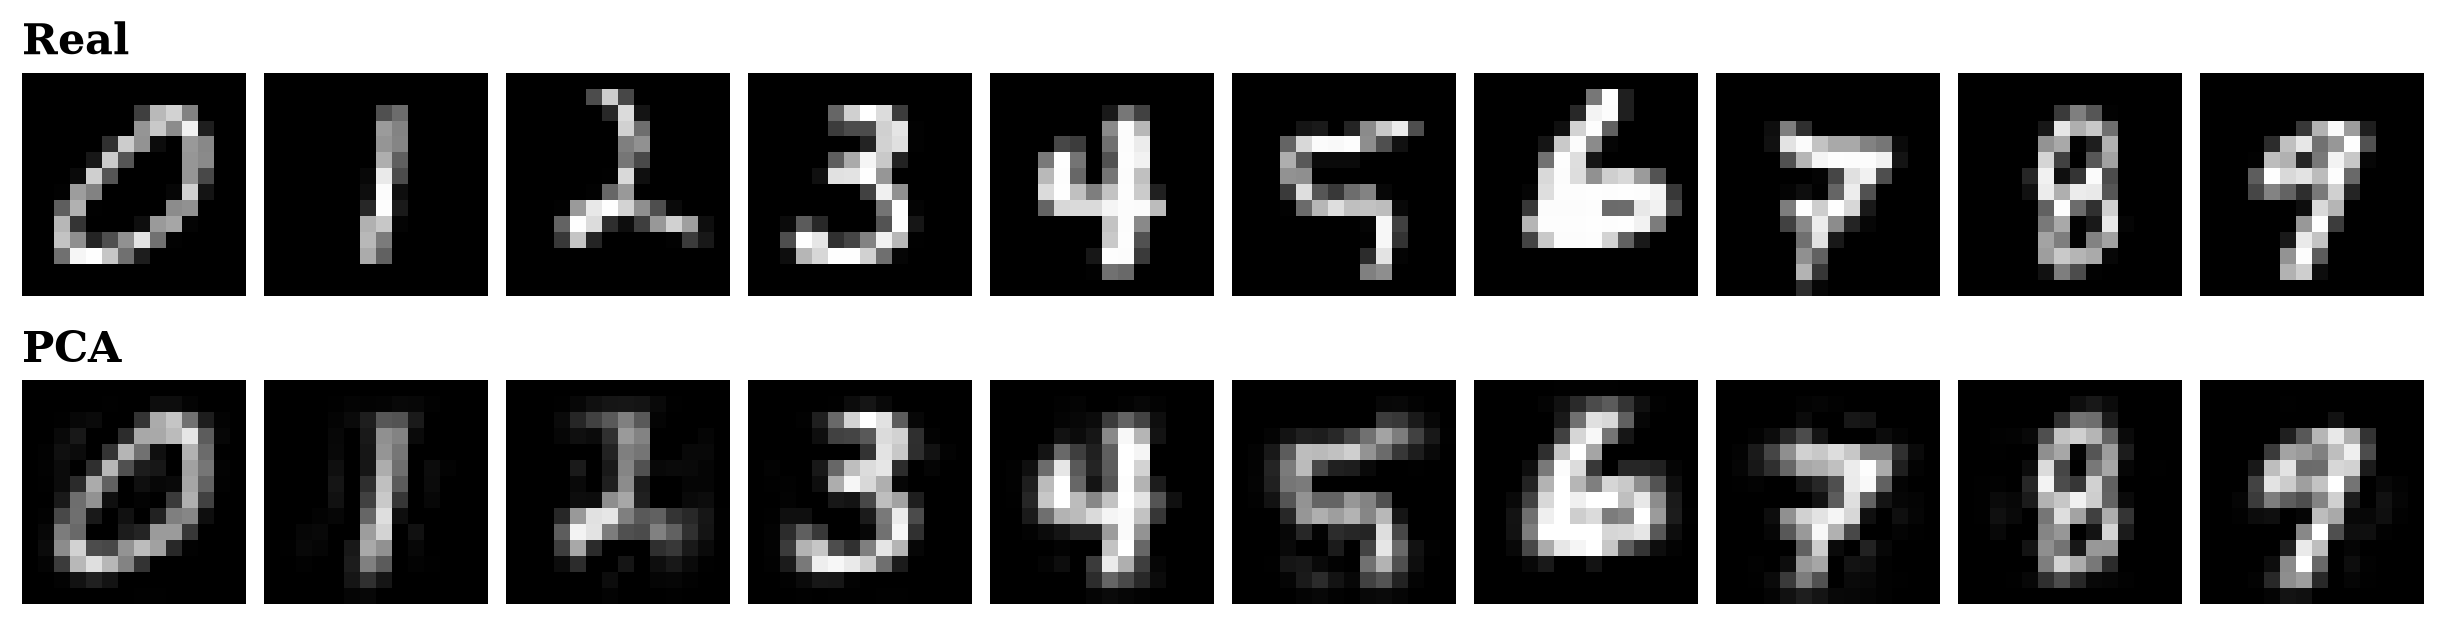

In [4]:
display(Image(filename=str(ROOT / 'assets/figures/pca_reconstruction.png')))

As reconstruções permitem avaliar o gargalo de compressão. Para SAR, a largura das pistas precisa de uma auditoria específica.